# XPS interface concentration depth

## 1. Problem

We reconstruct a **spatial chemical concentration field** across a liquid interface. This is an author-supplied simulated acquisition, not a measured sample. All 201 concentrations, including exterior and deep endpoints, are unknown. Ten photoelectron attenuation channels provide overlapping depth averages, so the inverse is highly underdetermined. The actual author chemical profile is used only for evaluation.

The selected comparison is a reproduction of the published Gaussian-prior, positive primal–dual algorithm with a fully free boundary configuration. It differs from the author's endpoint-conditioned example. No endpoint truth, privileged clean measurement or target-derived calibration enters reconstruction.

In [1]:
from pathlib import Path
import sys,time,os,json,hashlib
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import experiments,figures,metrics
from evaluation.judge import evaluate
data=load_data()
print('Actual kernel:',sys.executable)
print('NumPy:',np.__version__)
print('Public observation SHA256:',hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest())
print({k:(v.shape,str(v.dtype)) for k,v in data.items()})

Actual kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
NumPy: 2.4.6
Public observation SHA256: bfbc182d74558b5f2d76b585061c348308a76f878d3b2ac1f63558bc85dd65d9
{'observations': ((199, 10), 'float64'), 'system_matrix': ((10, 201), 'float64'), 'depth_nm': ((201,), 'float64'), 'attenuation_length_nm': ((10,), 'float64')}


## 2. Data

The licensed PROPHESY v0.3.0 release supplies the native ten-channel, 201-depth cylindrical calibration and 200 stored measurement rows. One stored row is exactly clean; it is **excluded**. All 199 noisy acquisitions are retained without quality selection. The nominal cylinder radius is 20 µm, illuminated length 200 µm, analyzer position (141.421356,0,100) µm. Depth increases from −2 to 20 nm in 0.11 nm steps. The known medium transition is 0.25 nm; this is separate from the unknown chemical field. The target-independent matrix is identical across the author's four chemical profiles.

No observations are generated for this task. An incomplete upstream generator references an absent smooth-interface quadrature helper, so acquisition regeneration is not claimed. The supplied calibrated system matrix is the acquisition operator. The general inverse package itself runs unchanged on these exact observations.

In [2]:
truth=np.load(ROOT/'evaluation/ground_truth.npz',allow_pickle=False)['reconstruction'][0]
upstream=np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False)['reconstruction'][0]
print('Attenuation lengths (nm):',data['attenuation_length_nm'])
print('Repeat SD:',data['observations'].std(0,ddof=1))
print('Mean standard error specified by acquisition:',.01/np.sqrt(199))

Attenuation lengths (nm): [1.28099588 1.80596848 2.31640359 2.80893249 3.28651268 3.75178459
 4.20674921 4.65291533 5.09144223 5.52324032]
Repeat SD: [0.00948343 0.01040788 0.00993103 0.01031363 0.01034799 0.00984464
 0.0094048  0.01036403 0.01019136 0.00943639]
Mean standard error specified by acquisition: 0.0007088812050083359


## 3. Physics

For repeat $k$, channel $i$ and depth sample $j$,

$$y_{ki}=\sum_jH_{ij}c_j+\epsilon_{ki}.$$

$c_j$ is relative chemical number density, $H_{ij}$ is the supplied cylindrical escape weight (µm³), and $y_{ki}$ is geometrically normalized peak area (µm³). The weights combine volume integration and exponential attenuation through the known total medium. Noise has independent standard deviation 0.01 µm³ before author positivity folding. Here all observed peak areas greatly exceed that scale. The mean of 199 repeats has covariance $\Gamma_y=(0.01^2/199)I$. The local forward and adjoint are explicit matrix multiplication; independent adjoint, linearity and units checks supplement source parity. Large attenuation lengths probe farther into the cylinder, but cannot restore information lost in near-null spatial modes.

## 4. Method

Let $D$ contain interior unscaled stencils $[-1,2,-1]$, with no prescribed endpoint. With $\Gamma_d=(201/10)0.01^2I$ and all entries initially 0.5, minimize

$$ (Hc-\bar y)^T\Gamma_y^{-1}(Hc-\bar y)+(Dc)^T\Gamma_d^{-1}Dc+\iota_{c\geq0}(c). $$

The diagonal prior is a documented choice supported by the published general solver; the second difference has no inverse-spacing-squared multiplier. For $A=[H;D]$, $b=[\bar y;0]$ and diagonal $C=\operatorname{diag}(\Gamma_y,\Gamma_d)$, the conjugate proximal is $(v-\sigma b)/(1+\sigma\operatorname{diag}(C)/2)$. Each step updates the dual, projects $c-\tau A^Ts$ onto nonnegative values, and extrapolates using $\theta=(1+2\gamma\tau)^{-1/2}$. Initially $\tau=10$, $\sigma=1/(\tau\|A\|_2^2)$ and $\gamma=2\sqrt{201}/10$; then $\tau\leftarrow\theta\tau$, $\sigma\leftarrow\sigma/\theta$.

The full budget is 100000 updates. Early stopping requires both median relative data residual ≤1e−4 and relative primal step ≤1e−9. The frozen original Julia run uses this same native dataset, configuration and all-unknown boundary. Its initial 50 updates were captured before local extraction.

In [3]:
start=time.perf_counter()
fresh,diagnostics=reconstruct(data['system_matrix'],data['observations'])
elapsed=time.perf_counter()-start
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=fresh[None])
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh.npz',reconstruction=fresh[None],history=diagnostics['history'])
print('Fresh complete reconstruction seconds:',elapsed,'updates:',diagnostics['iterations'])
print('Original / fresh NCC, range NRMSE:',metrics(upstream,truth),metrics(fresh,truth))
print('Original versus fresh maximum absolute error:',np.max(abs(fresh-upstream)))
report,status=evaluate(ROOT/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert status==0

Fresh complete reconstruction seconds: 4.961017699999502 updates: 100000
Original / fresh NCC, range NRMSE: (0.9982452869545168, 0.05658952983182777) (0.9982452869545226, 0.05658952983172945)
Original versus fresh maximum absolute error: 1.520894521434002e-12
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9982452869545226,
    "nrmse": 0.05658952983172945
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.8984207582590651
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.06224848281501055
    }
  },
  "errors": []
}


## 5. Results

All following curves and bars are computed from the current observations. We actively repeat the reconstruction for three prior strengths, three repeat counts and four iteration budgets. A general-purpose bound-constrained linear least-squares optimizer (BVLS, tolerance 1e?12) independently solves the same explicit quadratic objective; it diagnoses the selected finite CP budget and does not replace the published solver. The fresh CP, reproduced original CP and actual simulated truth remain separately identified.

NCC is cosine similarity without mean subtraction. NRMSE is RMS error divided by the truth's dynamic range. All 201 samples are evaluated without cropping, scaling or registration. A small data residual alone does not establish depth accuracy. Constant-density and zero controls reveal whether the spatial reconstruction is useful.

Fresh sensitivity/comparison runtime (s): 68.81547829999181
Independent QP success, iterations, objective, BVLS KKT optimality: [1.00000000e+00 1.60000000e+01 9.90567906e+00 1.57338847e-06]
Comparison                              NCC        Range NRMSE
prior_0.25                           0.99758576 0.06639876
prior_1.0                            0.99824529 0.05658953
prior_4.0                            0.99849236 0.05244749
repeats_1                            0.99336259 0.11020699
repeats_10                           0.99659434 0.07881252
repeats_199                          0.99824529 0.05658953
budget_100                           0.95512784 0.30529976
budget_1000                          0.98399693 0.17109594
budget_10000                         0.99046981 0.13173584
budget_100000                        0.99824529 0.05658953
independent_qp                       0.94758698 0.31749503
constant_air                         0.96021618 0.27929788
zero                                 0.

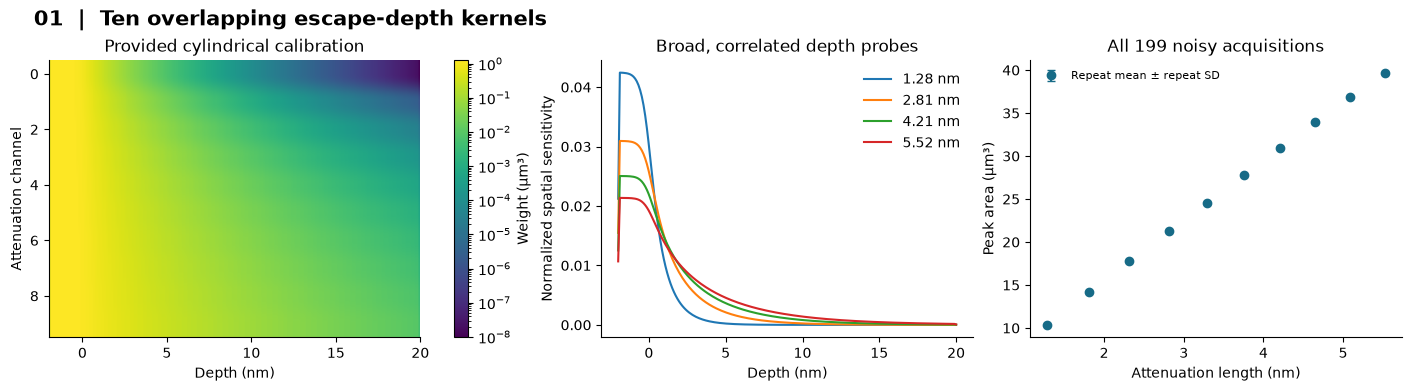

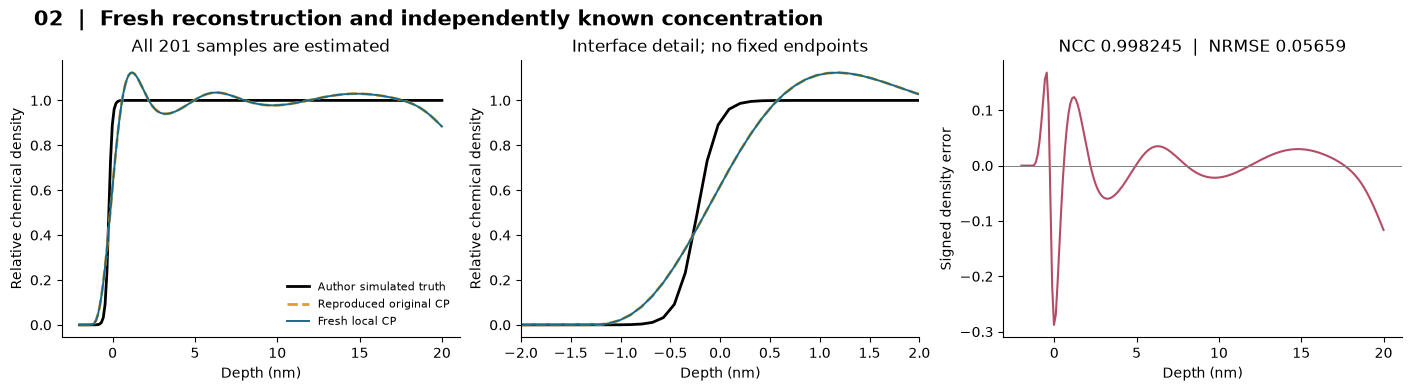

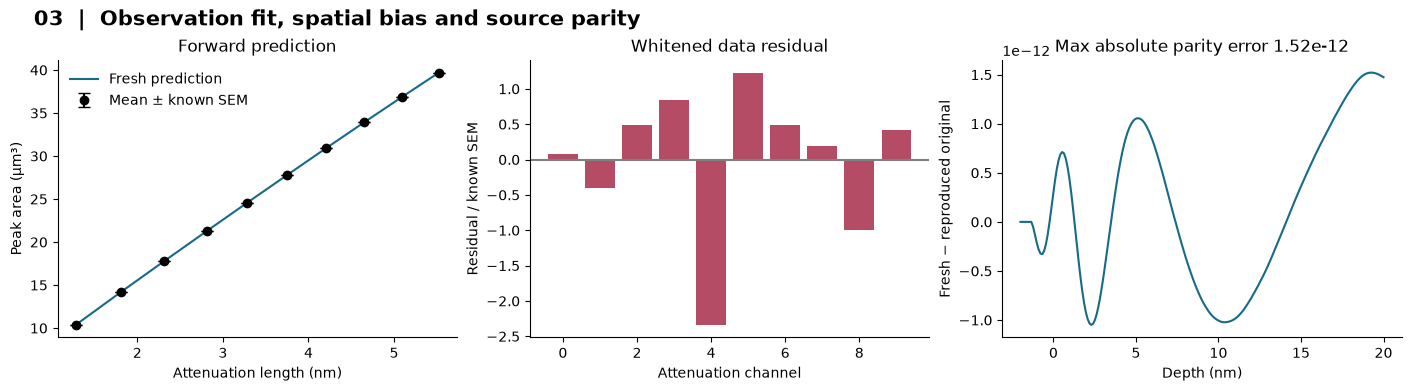

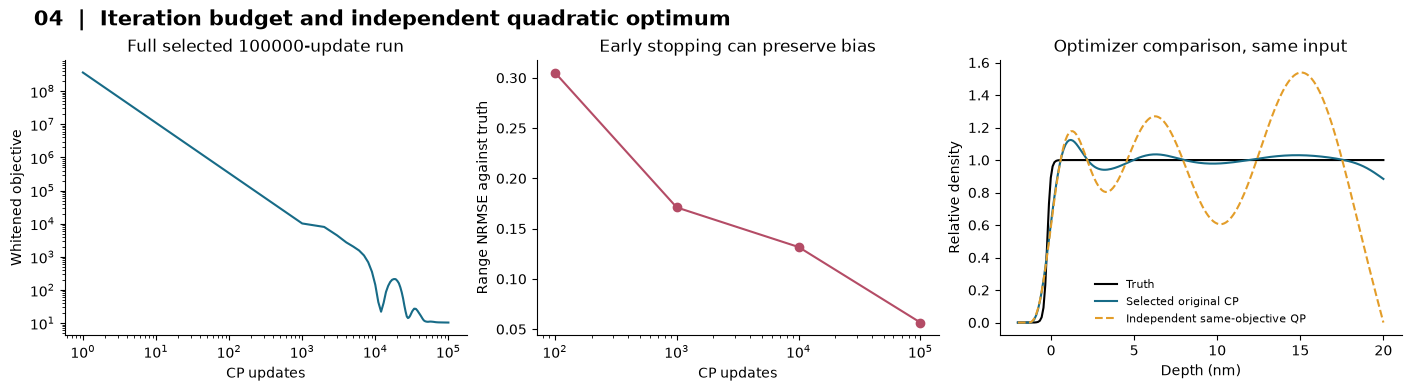

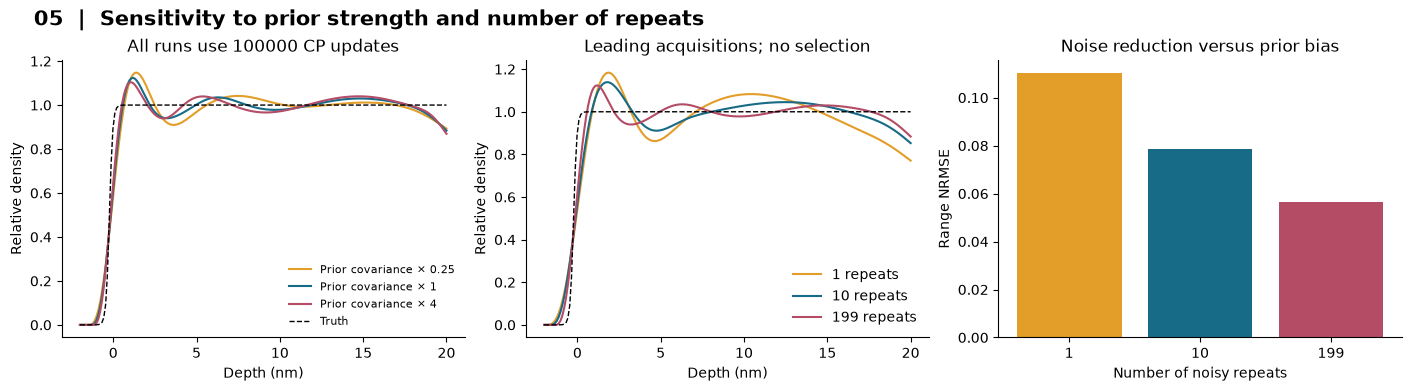

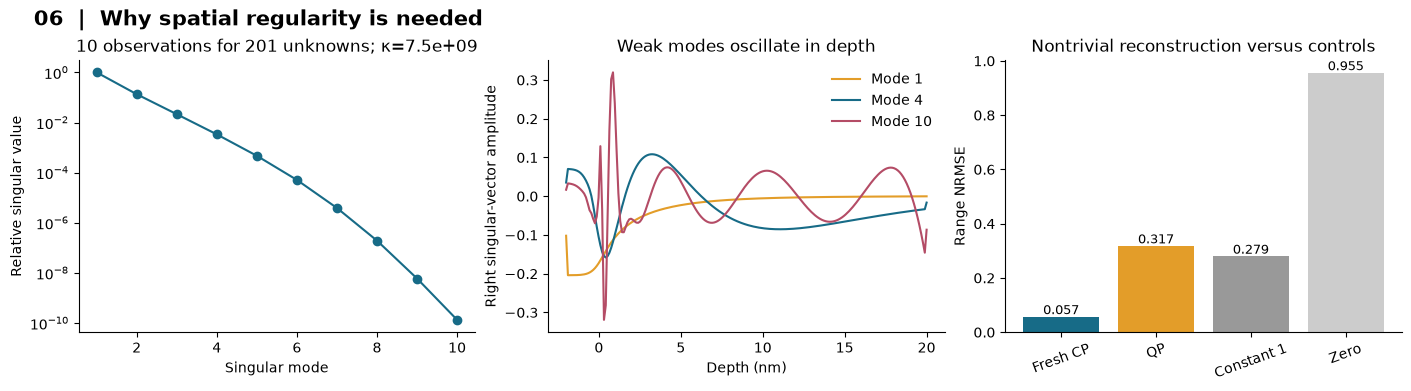

In [4]:
start=time.perf_counter()
comparisons=experiments(data,truth)
print('Fresh sensitivity/comparison runtime (s):',time.perf_counter()-start)
print('Independent QP success, iterations, objective, BVLS KKT optimality:',comparisons['qp_record'])
print('Comparison                              NCC        Range NRMSE')
for name,array in comparisons.items():
    if np.asarray(array).shape==truth.shape:
        n,e=metrics(array,truth);print(f'{name:36s} {n:.8f} {e:.8f}')
panels=figures(data,truth,fresh,diagnostics,comparisons,upstream)
export=os.environ.get('IMAGING101_XPS_EXPORT')
if export:
    target=Path(export);target.mkdir(parents=True,exist_ok=True)
    np.savez_compressed(target.parent/'xps_experiments.npz',fresh=fresh,truth=truth,upstream=upstream,history=diagnostics['history'],**comparisons)
for i,fig in enumerate(panels,1):
    if export:
        for ext in ['png','svg','pdf']:fig.savefig(target/f'xps-{i}.{ext}',dpi=170)
    display(fig)
    plt.close(fig)

## 6. Conclusion

The fresh implementation reproduces the original update path and full profile to floating-point precision while estimating every boundary value. The reconstructed interface and bulk density are useful under the all-depth metrics, but smoothness introduces interface and deep-field bias. Prior sensitivity, repeat-count sensitivity, singular modes and the independent quadratic optimum expose that limitation rather than interpreting source agreement as physical truth. The data are author simulations with independently supplied truth, not real measured evidence. Historical twenty-channel pilot runs and endpoint-conditioned examples are not represented as results of this ten-channel task.

The independent BVLS optimum lowers the objective from 10.3938 to 9.90568, yet worsens range NRMSE from 0.05659 to 0.31750. The finite original CP budget therefore supplies substantial implicit iterative regularization in this ill-conditioned acquisition. The selected result is a finite-budget reproduction, not a claim that CP has reached the constrained optimum. More exact objective minimization can fit weak spatial modes and worsen physical accuracy.

In [5]:
from src.physics_model import objective
y=data['observations'].mean(0);h=data['system_matrix']
print('Fresh objective:',objective(fresh,h,y,.01**2/199,201/10*.01**2))
print('QP objective:',objective(comparisons['independent_qp'],h,y,.01**2/199,201/10*.01**2))
assert len(panels)==6 and np.isfinite(fresh).all()
print('Complete active reconstruction, independent comparisons and six scientific figures finished.')

Fresh objective: 10.39380092389432
QP objective: 9.905679058278881
Complete active reconstruction, independent comparisons and six scientific figures finished.
